In [27]:
# ============================================================
# BHARATDOC AI
# PHASE 1.3: OCR BENCHMARKING
# ENVIRONMENT SETUP
# ============================================================

!apt-get update -qq
!apt-get install -y -qq tesseract-ocr
!apt-get install -y -qq tesseract-ocr-eng
!apt-get install -y -qq tesseract-ocr-hin
!apt-get install -y -qq tesseract-ocr-kan

%pip install -q pytesseract jiwer pandas pillow tqdm opencv-python-headless

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [28]:
from google.colab import drive

drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/BharatDocAI"
)

assert PROJECT_ROOT.exists()

print("Project directory:", PROJECT_ROOT)
print("Google Drive connected successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/BharatDocAI
Google Drive connected successfully!


In [29]:
import torch
import cv2
import pytesseract
import pandas as pd
import jiwer

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("OpenCV:", cv2.__version__)
print("Pandas:", pd.__version__)
print("Tesseract:", pytesseract.get_tesseract_version())

print(
    "Tesseract languages:",
    pytesseract.get_languages(config="")
)

print("\nEnvironment verification completed!")

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4
OpenCV: 4.14.0
Pandas: 2.2.3
Tesseract: 5.3.4
Tesseract languages: ['eng', 'hin', 'kan', 'osd']

Environment verification completed!


In [30]:
# ============================================================
# BHARATDOC AI: LOAD DATASET FOR OCR BENCHMARKING
# ============================================================

import json
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image
import pytesseract
import unicodedata
import re
from jiwer import cer, wer

PROJECT_ROOT = Path("/content/drive/MyDrive/BharatDocAI")

ANNOTATION_PATH = (
    PROJECT_ROOT / "data/annotations/synthetic_documents.jsonl"
)

DEGRADATION_MANIFEST = (
    PROJECT_ROOT / "data/processed/degradation_manifest.csv"
)

OCR_ROOT = PROJECT_ROOT / "data/ocr_outputs"
TESSERACT_DIR = OCR_ROOT / "tesseract"

TESSERACT_DIR.mkdir(parents=True, exist_ok=True)

# Load ground-truth annotations
with open(ANNOTATION_PATH, "r", encoding="utf-8") as f:
    annotations = [
        json.loads(line)
        for line in f if line.strip()
    ]

annotation_lookup = {
    record["document_id"]: record
    for record in annotations
}

# Load image manifest
image_manifest = pd.read_csv(DEGRADATION_MANIFEST)

# Attach ground truth
image_manifest["ground_truth"] = image_manifest[
    "document_id"
].map(
    lambda doc_id: annotation_lookup[doc_id]["document_text"]
)

assert len(annotations) == 90
assert len(image_manifest) == 1440
assert image_manifest["ground_truth"].notna().all()

print("Annotations:", len(annotations))
print("Image records:", len(image_manifest))
print("Ground-truth mapping verified!")

display(image_manifest.head())

Annotations: 90
Image records: 1440
Ground-truth mapping verified!


,document_id,language,category,template_family,split,corruption,severity,parameter,image_path,ground_truth
0,english_invoice_001,english,invoice,T1,train,clean,none,0.0,/content/drive/MyDrive/BharatDocAI/data/raw_do...,INVOICE\nCustomer Name: Kiran Rao\nInvoice Dat...
1,english_invoice_001,english,invoice,T1,train,gaussian_blur,mild,3.0,/content/drive/MyDrive/BharatDocAI/data/proces...,INVOICE\nCustomer Name: Kiran Rao\nInvoice Dat...
2,english_invoice_001,english,invoice,T1,train,gaussian_blur,moderate,5.0,/content/drive/MyDrive/BharatDocAI/data/proces...,INVOICE\nCustomer Name: Kiran Rao\nInvoice Dat...
3,english_invoice_001,english,invoice,T1,train,gaussian_blur,severe,7.0,/content/drive/MyDrive/BharatDocAI/data/proces...,INVOICE\nCustomer Name: Kiran Rao\nInvoice Dat...
4,english_invoice_001,english,invoice,T1,train,gaussian_noise,mild,10.0,/content/drive/MyDrive/BharatDocAI/data/proces...,INVOICE\nCustomer Name: Kiran Rao\nInvoice Dat...


In [31]:
# ============================================================
# TESSERACT OCR FUNCTION
# ============================================================

TESSERACT_LANGUAGES = {
    "english": "eng",
    "hindi": "hin",
    "kannada": "kan"
}

def run_tesseract(image_path, language):
    lang_map = {
        "english": "eng",
        "hindi": "hin",
        "kannada": "kan"
    }

    lang = lang_map[language]

    image = Image.open(image_path)

    text = pytesseract.image_to_string(
        image,
        lang=lang,
        config="--oem 3 --psm 3"
    )

    return text.strip()

print("Tesseract OCR function ready!")

Tesseract OCR function ready!


In [32]:
# ============================================================
# TESSERACT CLEAN DOCUMENT BENCHMARK
# ============================================================

clean_df = image_manifest[
    image_manifest["corruption"] == "clean"
].copy()

clean_results = []

for _, row in tqdm(
    clean_df.iterrows(),
    total=len(clean_df),
    desc="Tesseract clean OCR"
):

    try:
        prediction = run_tesseract(
            row["image_path"],
            row["language"]
        )

        status = "success"

    except Exception as e:
        prediction = ""
        status = f"error: {str(e)}"

    clean_results.append({
        "document_id": row["document_id"],
        "language": row["language"],
        "category": row["category"],
        "split": row["split"],
        "corruption": row["corruption"],
        "severity": row["severity"],
        "image_path": row["image_path"],
        "ground_truth": row["ground_truth"],
        "ocr_text": prediction,
        "status": status
    })

# Save results
clean_output_path = (
    TESSERACT_DIR / "tesseract_clean_results.jsonl"
)

with open(clean_output_path, "w", encoding="utf-8") as f:
    for result in clean_results:
        f.write(
            json.dumps(result, ensure_ascii=False) + "\n"
        )

print("\nClean OCR benchmark completed!")
print("Processed:", len(clean_results))
print("Successful:", sum(
    r["status"] == "success" for r in clean_results
))
print("Saved:", clean_output_path)

Tesseract clean OCR:   0%|          | 0/90 [00:00<?, ?it/s]


Clean OCR benchmark completed!
Processed: 90
Successful: 90
Saved: /content/drive/MyDrive/BharatDocAI/data/ocr_outputs/tesseract/tesseract_clean_results.jsonl


In [33]:
# ============================================================
# OCR METRIC CALCULATION
# ============================================================

def normalize_ocr_text(text):

    text = unicodedata.normalize("NFC", str(text))
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def calculate_ocr_metrics(results):

    rows = []

    for result in results:

        if result["status"] != "success":
            continue

        reference = normalize_ocr_text(
            result["ground_truth"]
        )

        prediction = normalize_ocr_text(
            result["ocr_text"]
        )

        character_error = cer(reference, prediction)
        word_error = wer(reference, prediction)

        rows.append({
            "document_id": result["document_id"],
            "language": result["language"],
            "category": result["category"],
            "split": result["split"],
            "corruption": result["corruption"],
            "severity": result["severity"],
            "CER": character_error,
            "WER": word_error,
            "character_accuracy": max(
                0, 1 - character_error
            )
        })

    return pd.DataFrame(rows)


clean_metrics = calculate_ocr_metrics(clean_results)

METRICS_DIR = PROJECT_ROOT / "outputs/metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

clean_metrics_path = (
    METRICS_DIR / "tesseract_clean_metrics.csv"
)

clean_metrics.to_csv(clean_metrics_path, index=False)

print("Clean OCR metrics by language:")

display(
    clean_metrics.groupby("language")[
        ["CER", "WER", "character_accuracy"]
    ].mean().round(4)
)

print("Saved:", clean_metrics_path)

Clean OCR metrics by language:


,CER,WER,character_accuracy
language,,,
english,0.2304,0.4719,0.7696
hindi,0.2681,0.4600,0.7319
kannada,0.2535,0.6038,0.7465


Saved: /content/drive/MyDrive/BharatDocAI/outputs/metrics/tesseract_clean_metrics.csv


Problematic documents: 0


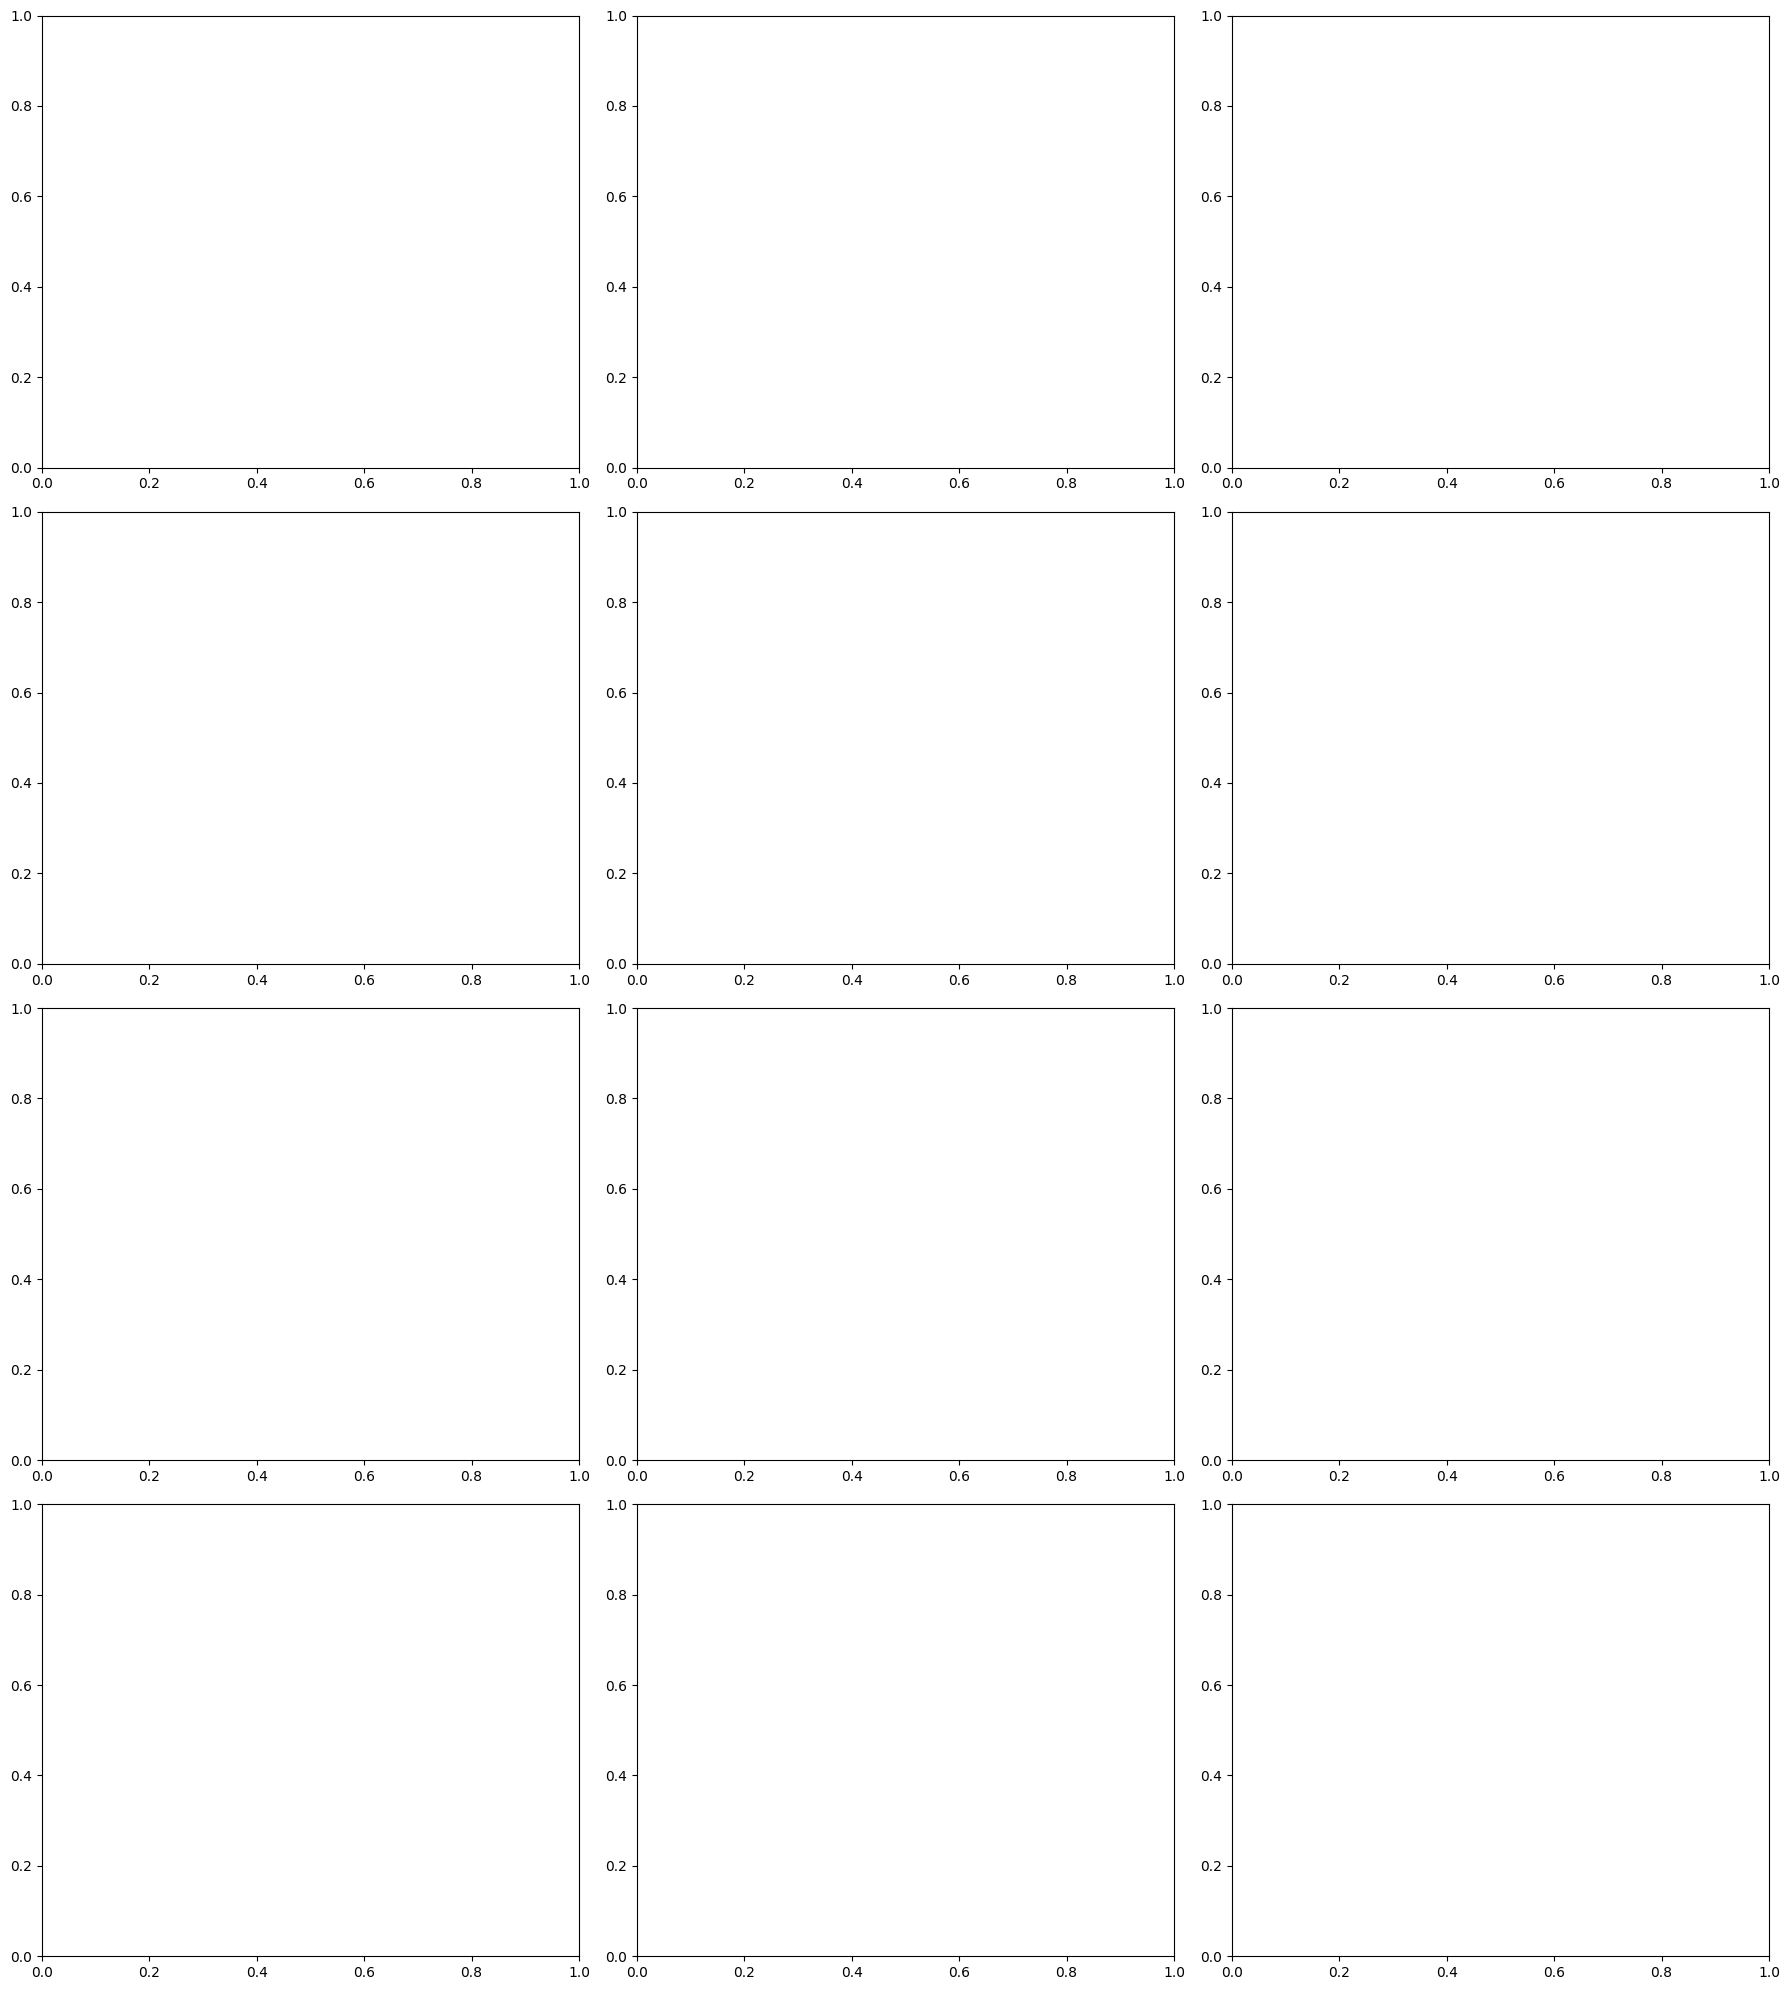

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os

metrics_path = os.path.join(
    PROJECT_ROOT,
    "outputs/metrics/tesseract_clean_metrics.csv"
)

metrics_df = pd.read_csv(metrics_path)

problem_ids = metrics_df[
    metrics_df["CER"] > 0.80
]["document_id"].tolist()

print("Problematic documents:", len(problem_ids))

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for ax, doc_id in zip(axes, problem_ids):
    image_path = os.path.join(
        PROJECT_ROOT,
        "data/raw_documents",
        doc_id + ".png"
    )

    img = Image.open(image_path)
    ax.imshow(img)
    ax.set_title(doc_id, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [35]:
from PIL import Image
import pytesseract
import pandas as pd

psm_modes = [3, 4, 6, 11]
diagnostic_results = []

for doc_id in problem_ids:

    row = metrics_df[
        metrics_df["document_id"] == doc_id
    ].iloc[0]

    image_path = os.path.join(
        PROJECT_ROOT,
        "data/raw_documents",
        doc_id + ".png"
    )

    img = Image.open(image_path)
    lang = {"english": "eng", "hindi": "hin", "kannada": "kan"}[
        row["language"]
    ]

    for psm in psm_modes:

        text = pytesseract.image_to_string(
            img,
            lang=lang,
            config=f"--oem 3 --psm {psm}"
        )

        diagnostic_results.append({
            "document_id": doc_id,
            "language": row["language"],
            "psm": psm,
            "ocr_text": text
        })

diagnostic_df = pd.DataFrame(diagnostic_results)

diagnostic_df.to_csv(
    os.path.join(
        PROJECT_ROOT,
        "outputs/metrics/tesseract_psm_diagnostic.csv"
    ),
    index=False
)

print("PSM diagnostic completed!")
display(diagnostic_df.head(16))

PSM diagnostic completed!


""


In [36]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import pandas as pd
import numpy as np
import pytesseract
import unicodedata
from PIL import Image
from tqdm.auto import tqdm
from jiwer import cer, wer
from collections import defaultdict

PROJECT_ROOT = "/content/drive/MyDrive/BharatDocAI"

ANNOTATION_PATH = os.path.join(
    PROJECT_ROOT, "data/annotations/synthetic_documents.jsonl"
)

MANIFEST_PATH = os.path.join(
    PROJECT_ROOT, "data/processed/degradation_manifest.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT, "data/ocr_outputs/tesseract"
)

METRICS_DIR = os.path.join(
    PROJECT_ROOT, "outputs/metrics"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Annotations exist:", os.path.exists(ANNOTATION_PATH))
print("Manifest exists:", os.path.exists(MANIFEST_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/BharatDocAI
Annotations exist: True
Manifest exists: True


In [39]:
with open(ANNOTATION_PATH, "r", encoding="utf-8") as f:
    annotations = [
        json.loads(line) for line in f if line.strip()
    ]

manifest_df = pd.read_csv(MANIFEST_PATH)

print("Total annotations:", len(annotations))
print("Total manifest records:", len(manifest_df))

print("\nManifest columns:")
print(manifest_df.columns.tolist())

print("\nFirst five records:")
display(manifest_df.head())

print("\nCorruption counts:")
print(manifest_df["corruption"].value_counts())

print("\nSeverity counts:")
print(manifest_df["severity"].value_counts())

print("\nSplit counts:")
print(manifest_df["split"].value_counts())

assert len(annotations) == 90
assert len(manifest_df) == 1440

print("\nManifest validation successful!")

Total annotations: 90
Total manifest records: 1440

Manifest columns:
['document_id', 'language', 'category', 'template_family', 'split', 'corruption', 'severity', 'parameter', 'image_path']

First five records:


,document_id,language,category,template_family,split,corruption,severity,parameter,image_path
0,english_invoice_001,english,invoice,T1,train,clean,none,0.0,/content/drive/MyDrive/BharatDocAI/data/raw_do...
1,english_invoice_001,english,invoice,T1,train,gaussian_blur,mild,3.0,/content/drive/MyDrive/BharatDocAI/data/proces...
2,english_invoice_001,english,invoice,T1,train,gaussian_blur,moderate,5.0,/content/drive/MyDrive/BharatDocAI/data/proces...
3,english_invoice_001,english,invoice,T1,train,gaussian_blur,severe,7.0,/content/drive/MyDrive/BharatDocAI/data/proces...
4,english_invoice_001,english,invoice,T1,train,gaussian_noise,mild,10.0,/content/drive/MyDrive/BharatDocAI/data/proces...



Corruption counts:
corruption
gaussian_blur       270
gaussian_noise      270
low_contrast        270
rotation            270
jpeg_compression    270
clean                90
Name: count, dtype: int64

Severity counts:
severity
mild        450
moderate    450
severe      450
none         90
Name: count, dtype: int64

Split counts:
split
train         864
validation    288
test          288
Name: count, dtype: int64

Manifest validation successful!


In [40]:
DOC_COL = "document_id"
IMAGE_COL = "image_path"
CORRUPTION_COL = "corruption"
SEVERITY_COL = "severity"
LANGUAGE_COL = "language"

# Exclude clean images
degraded_df = manifest_df[
    manifest_df[CORRUPTION_COL].str.lower() != "clean"
].copy()

print("Total degraded images:", len(degraded_df))

print("\nCorruption counts:")
print(degraded_df[CORRUPTION_COL].value_counts())

print("\nSeverity counts:")
print(degraded_df[SEVERITY_COL].value_counts())

assert len(degraded_df) == 1350

print("\nDegraded dataset preparation successful!")

Total degraded images: 1350

Corruption counts:
corruption
gaussian_blur       270
gaussian_noise      270
rotation            270
low_contrast        270
jpeg_compression    270
Name: count, dtype: int64

Severity counts:
severity
mild        450
moderate    450
severe      450
Name: count, dtype: int64

Degraded dataset preparation successful!


In [41]:
def resolve_image_path(value):
    path = str(value)

    if os.path.exists(path):
        return path

    raise FileNotFoundError(f"Image not found: {path}")

In [42]:
# Create ground-truth mapping

ground_truth = {
    item["document_id"]: item["document_text"]
    for item in annotations
}

language_map = {
    "english": "eng",
    "hindi": "hin",
    "kannada": "kan"
}

def resolve_image_path(value):
    path = str(value)

    if os.path.exists(path):
        return path

    raise FileNotFoundError(f"Image not found: {path}")


def run_tesseract(image_path, language):
    image = Image.open(image_path)

    text = pytesseract.image_to_string(
        image,
        lang=language_map[language],
        config="--oem 3 --psm 3"
    )

    return text.strip()


print("Ground-truth documents:", len(ground_truth))
print("OCR function ready!")

Ground-truth documents: 90
OCR function ready!


In [43]:
RESULT_PATH = os.path.join(
    OUTPUT_DIR,
    "tesseract_degraded_results.jsonl"
)

# Resume support
existing_results = []

if os.path.exists(RESULT_PATH):
    with open(RESULT_PATH, "r", encoding="utf-8") as f:
        existing_results = [
            json.loads(line)
            for line in f if line.strip()
        ]

processed_keys = {
    (
        item["document_id"],
        item["corruption"],
        item["severity"]
    )
    for item in existing_results
    if item.get("status") == "success"
}

print("Previously completed:", len(processed_keys))

with open(RESULT_PATH, "a", encoding="utf-8") as output_file:

    for _, row in tqdm(
        degraded_df.iterrows(),
        total=len(degraded_df),
        desc="Tesseract degraded OCR"
    ):

        doc_id = str(row["document_id"])
        corruption = str(row["corruption"])
        severity = str(row["severity"])

        key = (doc_id, corruption, severity)

        if key in processed_keys:
            continue

        try:
            language = str(row["language"]).lower()
            image_path = resolve_image_path(row["image_path"])

            if doc_id not in ground_truth:
                raise KeyError(f"Ground truth missing: {doc_id}")

            ocr_text = run_tesseract(image_path, language)

            result = {
                "document_id": doc_id,
                "language": language,
                "category": row["category"],
                "split": row["split"],
                "corruption": corruption,
                "severity": severity,
                "parameter": float(row["parameter"]),
                "image_path": image_path,
                "ground_truth": ground_truth[doc_id],
                "ocr_text": ocr_text,
                "status": "success"
            }

        except Exception as e:

            result = {
                "document_id": doc_id,
                "corruption": corruption,
                "severity": severity,
                "status": "error",
                "error": str(e)
            }

        output_file.write(
            json.dumps(result, ensure_ascii=False) + "\n"
        )
        output_file.flush()

print("\nDegraded OCR processing completed!")
print("Saved:", RESULT_PATH)

Previously completed: 0


Tesseract degraded OCR:   0%|          | 0/1350 [00:00<?, ?it/s]


Degraded OCR processing completed!
Saved: /content/drive/MyDrive/BharatDocAI/data/ocr_outputs/tesseract/tesseract_degraded_results.jsonl


In [44]:
with open(RESULT_PATH, "r", encoding="utf-8") as f:
    all_results = [
        json.loads(line)
        for line in f if line.strip()
    ]

successful_results = [
    item for item in all_results
    if item.get("status") == "success"
]

failed_results = [
    item for item in all_results
    if item.get("status") != "success"
]

print("Total result records:", len(all_results))
print("Successful:", len(successful_results))
print("Failed:", len(failed_results))

print("\nSuccessful records by corruption:")
print(pd.Series([
    item["corruption"] for item in successful_results
]).value_counts())

if failed_results:
    display(pd.DataFrame(failed_results).head())

assert len(successful_results) == 1350, (
    "Not all 1,350 images were processed successfully."
)

print("\nValidation successful!")

Total result records: 1350
Successful: 1350
Failed: 0

Successful records by corruption:
gaussian_blur       270
gaussian_noise      270
rotation            270
low_contrast        270
jpeg_compression    270
Name: count, dtype: int64

Validation successful!


In [45]:
def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text))
    text = " ".join(text.split())
    return text


evaluation_rows = []

for item in successful_results:

    reference = normalize_text(item["ground_truth"])
    hypothesis = normalize_text(item["ocr_text"])

    document_cer = cer(reference, hypothesis)
    document_wer = wer(reference, hypothesis)

    evaluation_rows.append({
        "document_id": item["document_id"],
        "language": item["language"],
        "category": item["category"],
        "split": item["split"],
        "corruption": item["corruption"],
        "severity": item["severity"],
        "parameter": item["parameter"],
        "CER": document_cer,
        "WER": document_wer,
        "character_accuracy": max(0, 1 - document_cer)
    })


evaluation_df = pd.DataFrame(evaluation_rows)

DETAIL_METRICS_PATH = os.path.join(
    METRICS_DIR,
    "tesseract_degraded_detailed_metrics.csv"
)

evaluation_df.to_csv(DETAIL_METRICS_PATH, index=False)

print("Evaluation completed!")
print("Evaluated documents:", len(evaluation_df))
print("Saved:", DETAIL_METRICS_PATH)

Evaluation completed!
Evaluated documents: 1350
Saved: /content/drive/MyDrive/BharatDocAI/outputs/metrics/tesseract_degraded_detailed_metrics.csv


In [46]:
# Language-wise performance

language_metrics = (
    evaluation_df
    .groupby("language")[["CER", "WER", "character_accuracy"]]
    .mean()
    .reset_index()
)

print("LANGUAGE-WISE RESULTS")
display(language_metrics)


# Corruption-wise performance

corruption_metrics = (
    evaluation_df
    .groupby("corruption")[["CER", "WER", "character_accuracy"]]
    .mean()
    .reset_index()
)

print("CORRUPTION-WISE RESULTS")
display(corruption_metrics)


# Severity-wise performance

severity_metrics = (
    evaluation_df
    .groupby("severity")[["CER", "WER", "character_accuracy"]]
    .mean()
    .reset_index()

)

print("SEVERITY-WISE RESULTS")
display(severity_metrics)


# Language x corruption

language_corruption_metrics = (
    evaluation_df
    .groupby(["language", "corruption"])
    [["CER", "WER", "character_accuracy"]]
    .mean()
    .reset_index()
)

print("LANGUAGE x CORRUPTION RESULTS")
display(language_corruption_metrics)


# Language x severity

language_severity_metrics = (
    evaluation_df
    .groupby(["language", "severity"])
    [["CER", "WER", "character_accuracy"]]
    .mean()
    .reset_index()
)

print("LANGUAGE x SEVERITY RESULTS")
display(language_severity_metrics)

LANGUAGE-WISE RESULTS


,language,CER,WER,character_accuracy
0,english,0.249308,0.502367,0.750692
1,hindi,0.330128,0.537071,0.670418
2,kannada,0.305607,0.631969,0.694393


CORRUPTION-WISE RESULTS


,corruption,CER,WER,character_accuracy
0,gaussian_blur,0.310724,0.551327,0.689276
1,gaussian_noise,0.349248,0.571886,0.650752
2,jpeg_compression,0.257801,0.513409,0.742199
3,low_contrast,0.251392,0.517435,0.748608
4,rotation,0.305908,0.631622,0.695003


SEVERITY-WISE RESULTS


,severity,CER,WER,character_accuracy
0,mild,0.265410,0.521351,0.735137
1,moderate,0.286113,0.550889,0.713887
2,severe,0.333521,0.599166,0.666479


LANGUAGE x CORRUPTION RESULTS


,language,corruption,CER,WER,character_accuracy
0,english,gaussian_blur,0.231719,0.493019,0.768281
1,english,gaussian_noise,0.304316,0.518891,0.695684
2,english,jpeg_compression,0.231766,0.471895,0.768234
3,english,low_contrast,0.230489,0.471895,0.769511
4,english,rotation,0.248249,0.556137,0.751751
5,hindi,gaussian_blur,0.365039,0.560758,0.634961
6,hindi,gaussian_noise,0.375018,0.551383,0.624982
7,hindi,jpeg_compression,0.268345,0.465799,0.731655
8,hindi,low_contrast,0.265598,0.458962,0.734402
9,hindi,rotation,0.376642,0.648452,0.626092


LANGUAGE x SEVERITY RESULTS


,language,severity,CER,WER,character_accuracy
0,english,mild,0.217461,0.465245,0.782539
1,english,moderate,0.248779,0.506462,0.751221
2,english,severe,0.281683,0.535395,0.718317
3,hindi,mild,0.317406,0.499937,0.684234
4,hindi,moderate,0.320637,0.527701,0.679363
5,hindi,severe,0.352342,0.583575,0.647658
6,kannada,mild,0.261361,0.598873,0.738639
7,kannada,moderate,0.288924,0.618505,0.711076
8,kannada,severe,0.366537,0.678529,0.633463


In [47]:
language_metrics.to_csv(
    os.path.join(METRICS_DIR, "tesseract_degraded_by_language.csv"),
    index=False
)

corruption_metrics.to_csv(
    os.path.join(METRICS_DIR, "tesseract_degraded_by_corruption.csv"),
    index=False
)

severity_metrics.to_csv(
    os.path.join(METRICS_DIR, "tesseract_degraded_by_severity.csv"),
    index=False
)

language_corruption_metrics.to_csv(
    os.path.join(METRICS_DIR, "tesseract_degraded_language_corruption.csv"),
    index=False
)

language_severity_metrics.to_csv(
    os.path.join(METRICS_DIR, "tesseract_degraded_language_severity.csv"),
    index=False
)

print("All summary metrics saved successfully!")

All summary metrics saved successfully!


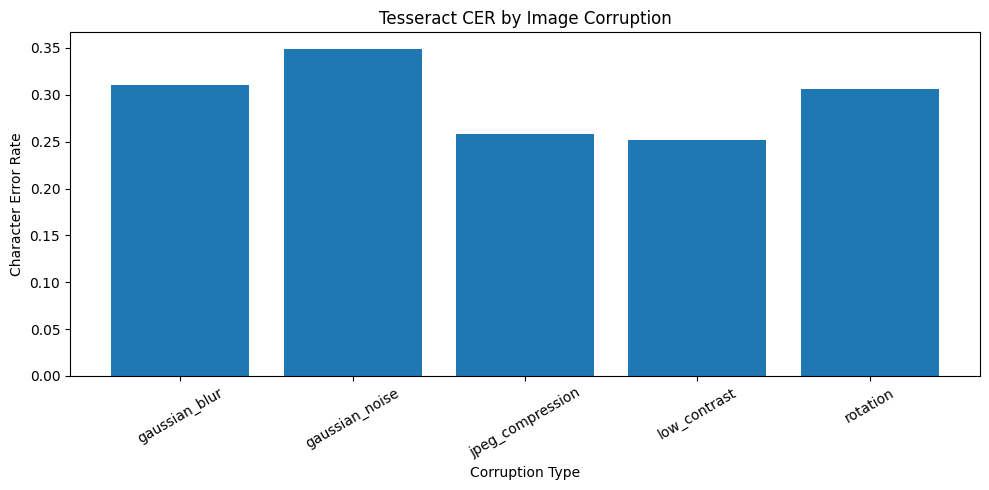

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    corruption_metrics["corruption"],
    corruption_metrics["CER"]
)

plt.title("Tesseract CER by Image Corruption")
plt.xlabel("Corruption Type")
plt.ylabel("Character Error Rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

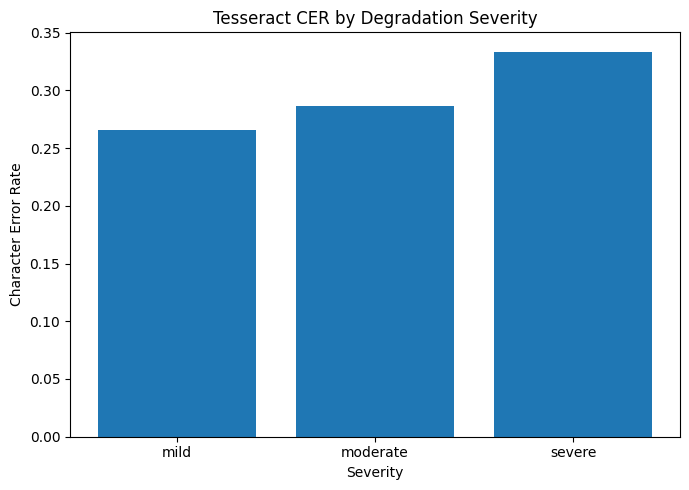

In [49]:
severity_order = ["mild", "moderate", "severe"]

plot_df = severity_metrics.copy()

plot_df["severity"] = pd.Categorical(
    plot_df["severity"],
    categories=severity_order,
    ordered=True
)

plot_df = plot_df.sort_values("severity")

plt.figure(figsize=(7, 5))

plt.bar(
    plot_df["severity"].astype(str),
    plot_df["CER"]
)

plt.title("Tesseract CER by Degradation Severity")
plt.xlabel("Severity")
plt.ylabel("Character Error Rate")
plt.tight_layout()
plt.show()

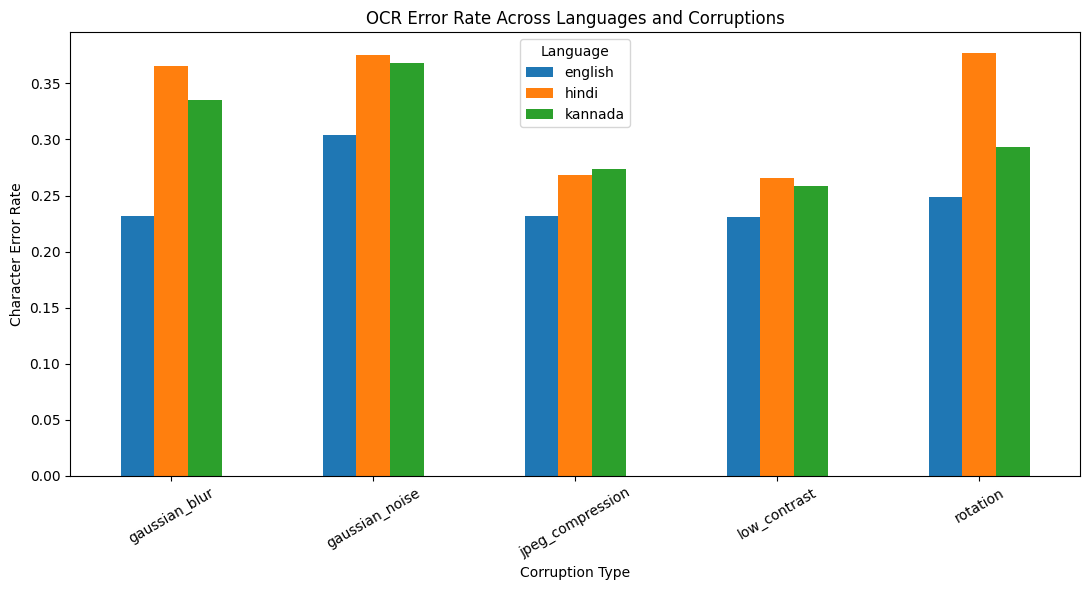

In [50]:
pivot_df = evaluation_df.pivot_table(
    index="corruption",
    columns="language",
    values="CER",
    aggfunc="mean"
)

pivot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("OCR Error Rate Across Languages and Corruptions")
plt.xlabel("Corruption Type")
plt.ylabel("Character Error Rate")
plt.xticks(rotation=30)
plt.legend(title="Language")
plt.tight_layout()
plt.show()

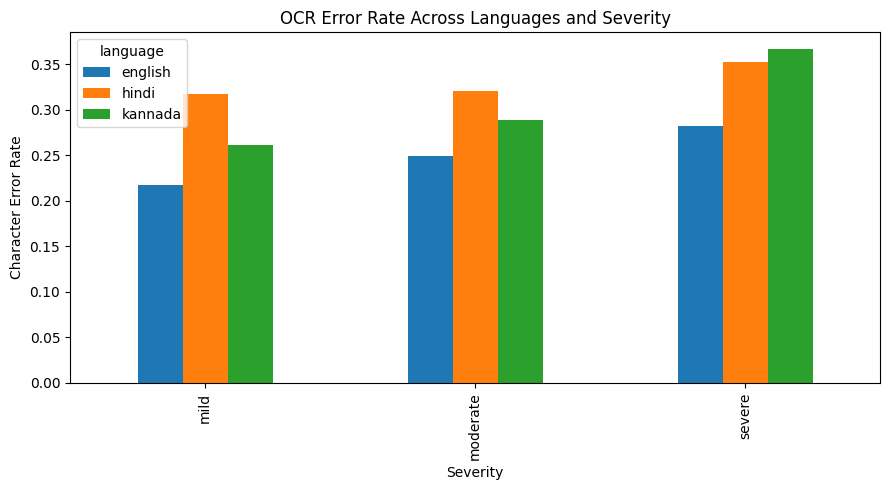

In [51]:
pivot_severity = evaluation_df.pivot_table(
    index="severity",
    columns="language",
    values="CER",
    aggfunc="mean"
)

pivot_severity = pivot_severity.reindex(
    ["mild", "moderate", "severe"]
)

pivot_severity.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("OCR Error Rate Across Languages and Severity")
plt.xlabel("Severity")
plt.ylabel("Character Error Rate")
plt.tight_layout()
plt.show()

In [52]:
def grouped_metrics(df, group_columns):
    result = (
        df.groupby(group_columns)
        .agg(
            CER=("CER", "mean"),
            WER=("WER", "mean")
        )
        .reset_index()
    )

    result["character_accuracy"] = 1 - result["CER"]

    return result


language_metrics = grouped_metrics(
    evaluation_df, ["language"]
)

corruption_metrics = grouped_metrics(
    evaluation_df, ["corruption"]
)

severity_metrics = grouped_metrics(
    evaluation_df, ["severity"]
)

language_corruption_metrics = grouped_metrics(
    evaluation_df, ["language", "corruption"]
)

language_severity_metrics = grouped_metrics(
    evaluation_df, ["language", "severity"]
)

print("Updated language metrics")
display(language_metrics)

print("Updated corruption metrics")
display(corruption_metrics)

print("Updated severity metrics")
display(severity_metrics)

Updated language metrics


,language,CER,WER,character_accuracy
0,english,0.249308,0.502367,0.750692
1,hindi,0.330128,0.537071,0.669872
2,kannada,0.305607,0.631969,0.694393


Updated corruption metrics


,corruption,CER,WER,character_accuracy
0,gaussian_blur,0.310724,0.551327,0.689276
1,gaussian_noise,0.349248,0.571886,0.650752
2,jpeg_compression,0.257801,0.513409,0.742199
3,low_contrast,0.251392,0.517435,0.748608
4,rotation,0.305908,0.631622,0.694092


Updated severity metrics


,severity,CER,WER,character_accuracy
0,mild,0.265410,0.521351,0.734590
1,moderate,0.286113,0.550889,0.713887
2,severe,0.333521,0.599166,0.666479
